In [5]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from initial_state import ValidationSpec
from controllers.sindy_lqr import SINDyLQRController
from models.sindy import SINDyConfig, SINDyDynamicsModel
from models.dataset_views import (
    load_control_dataset, flatten_supervised, kfold_stratified_by_angle,
)
from models.lqr_utils import discrete_lqr_gain
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics

DATASET      = ROOT / "data/full_example/random_walk_dataset.npz"
ARTIFACT     = ROOT / "artifacts/controllers/sindy_lqr.pkl"
VAL_SPEC     = ROOT / "artifacts/validation/sindy_lqr_val_spec.npz"
VAL_ROLLOUTS = ROOT / "artifacts/validation/sindy_lqr_stress_rollouts.npz"
FOLD_METRICS = ROOT / "artifacts/validation/sindy_lqr_fold_metrics.npz"

N_FOLDS     = 5
T_END       = 20.0
DT          = 0.02
FORCE_LIMIT = 5.0
SEED        = 0

## 1. Load Validation Spec and Baseline Rollouts

Requires `05a_sindy_lqr_stress_test.ipynb` to have been run so that the
validation spec and the 100 baseline-controller rollout arrays exist.

In [6]:
for path in (VAL_SPEC, VAL_ROLLOUTS):
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found.\n"
            "Run notebooks/05a_sindy_lqr_stress_test.ipynb first."
        )

spec = ValidationSpec.load(VAL_SPEC)
feas_idx = np.where(spec.feasible)[0]   # global indices of feasible cases
n_feas   = len(feas_idx)
print(f"Validation spec: {n_feas}/{spec.n} feasible cases")
print(f"  angle range: [{spec.angles_deg[feas_idx].min():.1f}, "
      f"{spec.angles_deg[feas_idx].max():.1f}] deg")
print(f"  force range: [{spec.forces[feas_idx].min():.2f}, "
      f"{spec.forces[feas_idx].max():.2f}] N")

_d = np.load(VAL_ROLLOUTS)
states_arr = _d["states"]           # (N, 4, n_steps) baseline rollouts
inputs_arr = _d["inputs"]           # (N, n_steps)
t_arr      = _d["t"]                # (n_steps,)
rollout_ok = _d["success"].astype(bool)
print(f"Loaded baseline rollouts: {rollout_ok.sum()} successful")

Validation spec: 100/100 feasible cases
  angle range: [6.8, 89.4] deg
  force range: [0.53, 4.89] N
Loaded baseline rollouts: 100 successful


## 2. Original Training Dataset

Extract all (state, input, next-state) transition pairs from the original
random-walk dataset.  These pairs appear in the training set for every fold.

In [7]:
ds = load_control_dataset(DATASET)
all_traj_idx = np.arange(ds.num_trajectories)
x_orig, _, x_next_orig = flatten_supervised(ds, all_traj_idx)
print(f"Original dataset: {x_orig.shape[0]:,} transition pairs "
      f"from {ds.num_trajectories} trajectories  (dt={ds.dt:.4f} s)")

Original dataset: 499,500 transition pairs from 500 trajectories  (dt=0.0100 s)


## 3. Baseline Controller and Hyperparameters

Read the tuned (threshold, ridge, alpha) from the baseline artifact so every
fold uses the same SINDy configuration and LQR weights, making the cross-
validation a test of generalization rather than a different controller recipe.

In [8]:
if not ARTIFACT.exists():
    raise FileNotFoundError(
        f"{ARTIFACT} not found.\n"
        "Run notebooks/05_sindy_lqr.ipynb first."
    )

baseline = SINDyLQRController.load(ARTIFACT)
best_thr   = baseline.metadata["model"]["config"]["threshold"]
best_ridge = baseline.metadata["model"]["config"]["ridge"]
best_alpha = float(baseline.metadata["alpha"])
q          = np.asarray(baseline.metadata["Q"])
r          = np.asarray(baseline.metadata["R"])

print(f"Baseline hyperparams:")
print(f"  threshold={best_thr}  ridge={best_ridge}  alpha={best_alpha}")
print(f"  force_limit={baseline.force_limit} N")

Baseline hyperparams:
  threshold=0.005  ridge=0.0001  alpha=0.75
  force_limit=5.0 N


## 4. Five-Fold Stratified Splits

Cases are sorted by target angle and assigned to folds in round-robin order
so each held-out fold spans the full angle range.

In [9]:
feas_angles = spec.angles_deg[feas_idx]   # (n_feas,)
splits = kfold_stratified_by_angle(n_feas, feas_angles, k=N_FOLDS, seed=SEED)

print(f"{N_FOLDS}-fold stratified splits:")
for fold, (train_i, val_i) in enumerate(splits):
    val_angles  = feas_angles[val_i]
    print(f"  Fold {fold + 1}: train={len(train_i)}  val={len(val_i)}  "
          f"val_angle=[{val_angles.min():.1f}, {val_angles.max():.1f}] deg")

5-fold stratified splits:
  Fold 1: train=80  val=20  val_angle=[6.8, 84.7] deg
  Fold 2: train=80  val=20  val_angle=[6.9, 86.0] deg
  Fold 3: train=80  val=20  val_angle=[8.2, 86.5] deg
  Fold 4: train=80  val=20  val_angle=[8.5, 87.4] deg
  Fold 5: train=80  val=20  val_angle=[8.8, 89.4] deg


## 5. Cross-Validation Loop

For each fold:
1. Combine original dataset pairs with the 80 training-fold baseline rollouts.
2. Fit SINDy on the combined data (same hyperparams as the baseline).
3. Compute LQR gain from the learned A, B matrices.
4. Run rollouts from the 20 held-out initial states using the new controller.
5. Record rollout metrics.

In [10]:
fold_results = []
fold_equations = []

for fold, (train_i, val_i) in enumerate(splits):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} ---")

    # --- Build augmented training pairs ---
    # Each train-fold rollout: states (4, n_steps), inputs (n_steps,)
    zu_list, xn_list = [], []
    for local_i in train_i:
        global_i = int(feas_idx[local_i])
        if not rollout_ok[global_i]:
            continue
        s = states_arr[global_i]       # (4, n_steps)
        u = inputs_arr[global_i]       # (n_steps,)
        sk = s.T[:-1]                  # (n_steps-1, 4)
        uk = u[:-1, None]              # (n_steps-1, 1)
        zu = np.concatenate([sk, uk], axis=1)  # (n_steps-1, 5)
        xn = s.T[1:]                   # (n_steps-1, 4)
        if np.all(np.isfinite(zu)) and np.all(np.isfinite(xn)):
            zu_list.append(zu)
            xn_list.append(xn)

    if zu_list:
        x_fold = np.vstack(zu_list)
        x_next_fold = np.vstack(xn_list)
        x_combined = np.vstack([x_orig, x_fold])
        x_next_combined = np.vstack([x_next_orig, x_next_fold])
        rollout_pairs_added = x_fold.shape[0]
    else:
        x_combined = x_orig
        x_next_combined = x_next_orig
        rollout_pairs_added = 0

    print(f"  Training pairs: {x_orig.shape[0]:,} original + "
          f"{rollout_pairs_added:,} rollout = {x_combined.shape[0]:,} total")

    # --- Fit SINDy model ---
    config = SINDyConfig(threshold=best_thr, ridge=best_ridge)
    model = SINDyDynamicsModel(config=config).fit(x_combined, x_next_combined)
    a, b = model.linearize()
    k_gain, _ = discrete_lqr_gain(a, b, q, r)
    fold_ctrl = SINDyLQRController(
        model=model, k=k_gain, q=q, r=r,
        force_limit=FORCE_LIMIT, alpha=best_alpha,
    )
    fold_equations.append(model.equations())
    print("  Learned equations:")
    for eq in model.equations():
        print(f"    {eq}")

    # --- Evaluate on held-out initial states ---
    for local_i in val_i:
        global_i = int(feas_idx[local_i])
        x0 = spec.initial_states[global_i]
        result = rollout_controller(
            fold_ctrl, x0, t_end=T_END, dt=DT, force_limit=FORCE_LIMIT,
        )
        m = rollout_metrics(result.t, result.y, result.u, result.control_times_sec)
        fold_results.append({
            "case":      global_i,
            "fold":      fold,
            "angle_deg": float(spec.angles_deg[global_i]),
            "force_N":   float(spec.forces[global_i]),
            **m,
        })

    fold_succ = sum(1 for r in fold_results if r["fold"] == fold and r.get("success"))
    fold_n    = sum(1 for r in fold_results if r["fold"] == fold)
    print(f"  Fold {fold + 1} held-out: {fold_succ}/{fold_n} success")

print(f"\n=== Cross-validation complete: {len(fold_results)} held-out evaluations ===")


--- Fold 1/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Learned equations:
    x_next = 1*x + 0.01912*x_dot
    x_dot_next = 1*x_dot + 0.01486*u + -0.03046*sin(theta)
    theta_next = 1*theta + 0.01094*theta_dot
    theta_dot_next = 1*theta_dot + -0.01684*u + -0.006953*theta_dot^2 + 0.225*sin(theta) + -0.2971*cos(theta)-1 + 0.03373*u*cos(theta)
  Fold 1 held-out: 1/20 success

--- Fold 2/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Learned equations:
    x_next = 1*x + 0.01913*x_dot
    x_dot_next = 1*x_dot + 0.01486*u + -0.03046*sin(theta)
    theta_next = 1*theta + 0.01093*theta_dot
    theta_dot_next = 1*theta_dot + -0.01653*u + -0.006907*theta_dot^2 + 0.225*sin(theta) + -0.2953*cos(theta)-1 + 0.0335*u*cos(theta)
  Fold 2 held-out: 1/20 success

--- Fold 3/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Learned equations:
    x_next = 1*x + 0.01914*x_dot
    x_dot_next = 1*x_dot + 0.01483*u + 

## 6. Results

In [11]:
# Per-fold summary
print(f"{'Fold':>5}  {'n':>4}  {'success':>8}  {'succ%':>6}  "
      f"{'settle_med':>10}  {'cost_med':>8}")
print("-" * 55)
for fold in range(N_FOLDS):
    fold_recs = [r for r in fold_results if r["fold"] == fold]
    n_f = len(fold_recs)
    succ_f = sum(1 for r in fold_recs if r.get("success"))
    costs_f = [r["cost"] for r in fold_recs if "cost" in r]
    st_f    = [r["settle_and_remain_time"] for r in fold_recs
               if r.get("settle_and_remain_time") is not None]
    print(f"{fold + 1:>5}  {n_f:>4}  {succ_f:>8}  "
          f"{100 * succ_f / max(1, n_f):>5.1f}%  "
          f"{np.median(st_f) if st_f else float('nan'):>10.2f}  "
          f"{np.median(costs_f) if costs_f else float('nan'):>8.1f}")

print("-" * 55)
total_succ = sum(1 for r in fold_results if r.get("success"))
total_n    = len(fold_results)
all_costs  = [r["cost"] for r in fold_results if "cost" in r]
all_st     = [r["settle_and_remain_time"] for r in fold_results
              if r.get("settle_and_remain_time") is not None]
print(f"{'CV':>5}  {total_n:>4}  {total_succ:>8}  "
      f"{100 * total_succ / max(1, total_n):>5.1f}%  "
      f"{np.median(all_st) if all_st else float('nan'):>10.2f}  "
      f"{np.median(all_costs) if all_costs else float('nan'):>8.1f}")

 Fold     n   success   succ%  settle_med  cost_med
-------------------------------------------------------
    1    20         1    5.0%        3.58  128414009.3
    2    20         1    5.0%        3.60  129816427.2
    3    20         1    5.0%        4.02  130267602.3
    4    20         1    5.0%        4.16  130487389.3
    5    20         1    5.0%        4.24  131717324.2
-------------------------------------------------------
   CV   100         5    5.0%        4.02  129706483.7


In [12]:
# Compare CV results against baseline on the same initial conditions
from initial_state import ValidationSpec  # already imported above

# Load baseline stress-test metrics if available
baseline_metrics_path = ROOT / "artifacts/validation/sindy_lqr_stress_metrics.npz"
if baseline_metrics_path.exists():
    bm = np.load(baseline_metrics_path)

    # Restrict comparison to cases covered by cross-validation
    cv_cases = {r["case"] for r in fold_results}
    baseline_succ = [float(bm["success"][i])
                     for i in cv_cases if np.isfinite(bm["success"][i])]
    baseline_cost = [float(bm["cost"][i])
                     for i in cv_cases if np.isfinite(bm["cost"][i])]

    cv_succ_vals   = [float(r.get("success", 0)) for r in fold_results]
    cv_cost_vals   = [float(r["cost"]) for r in fold_results if "cost" in r]

    print("Comparison on the same initial conditions:")
    print(f"  Baseline success rate:  "
          f"{np.nansum(baseline_succ):.0f}/{len(baseline_succ)}  "
          f"({100 * np.nanmean(baseline_succ):.1f}%)")
    print(f"  CV controller success:  "
          f"{sum(r.get('success', False) for r in fold_results)}/{len(fold_results)}  "
          f"({100 * total_succ / max(1, total_n):.1f}%)")
    if baseline_cost:
        print(f"  Baseline median cost:   {np.median(baseline_cost):.1f}")
    if cv_cost_vals:
        print(f"  CV median cost:         {np.median(cv_cost_vals):.1f}")
else:
    print("Baseline stress metrics not found; run 05a_sindy_lqr_stress_test.ipynb "
          "and save metrics to enable the comparison table.")

Comparison on the same initial conditions:
  Baseline success rate:  5/100  (5.0%)
  CV controller success:  5/100  (5.0%)
  Baseline median cost:   129706483.7
  CV median cost:         129706483.7


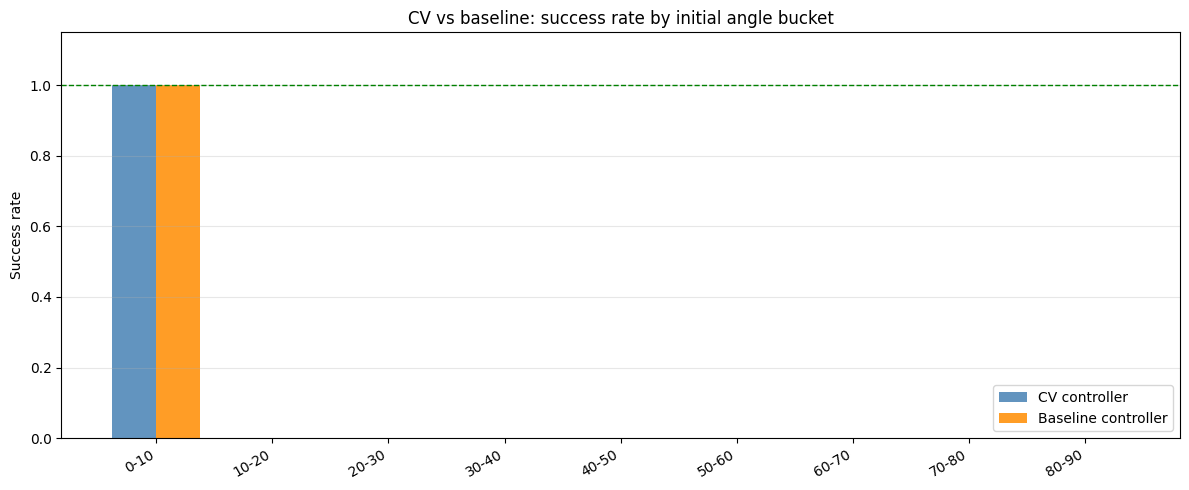

In [13]:
# Plot: success rate by angle bucket for CV vs baseline
angle_bins = np.arange(0, 100, 10)
bucket_labels = [f"{int(b)}-{int(b+10)}" for b in angle_bins[:-1]]

cv_succ_rates = []
bl_succ_rates = []
for lo, hi in zip(angle_bins[:-1], angle_bins[1:]):
    cv_bucket = [r for r in fold_results
                 if lo <= r["angle_deg"] < hi]
    cv_succ_rates.append(
        sum(1 for r in cv_bucket if r.get("success")) / max(1, len(cv_bucket))
    )

    if baseline_metrics_path.exists():
        bl_bucket_succ = [
            float(bm["success"][i])
            for i in cv_cases
            if lo <= float(spec.angles_deg[i]) < hi
            and np.isfinite(bm["success"][i])
        ]
        bl_succ_rates.append(np.mean(bl_bucket_succ) if bl_bucket_succ else np.nan)
    else:
        bl_succ_rates.append(np.nan)

x_pos = np.arange(len(bucket_labels))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x_pos - width / 2, cv_succ_rates, width=width,
       color="steelblue", alpha=0.85, label="CV controller")
if any(not np.isnan(v) for v in bl_succ_rates):
    ax.bar(x_pos + width / 2, bl_succ_rates, width=width,
           color="darkorange", alpha=0.85, label="Baseline controller")
ax.set_xticks(x_pos)
ax.set_xticklabels(bucket_labels, rotation=30, ha="right")
ax.set_ylabel("Success rate")
ax.set_title("CV vs baseline: success rate by initial angle bucket")
ax.set_ylim(0, 1.15)
ax.axhline(1.0, color="green", linestyle="--", linewidth=1)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Save Fold Artifacts

In [14]:
def _to_float(v):
    if v is None:
        return np.nan
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan


fold_metrics_to_save = {
    "case":               np.array([r["case"]         for r in fold_results]),
    "fold":               np.array([r["fold"]         for r in fold_results]),
    "angle_deg":          np.array([r["angle_deg"]    for r in fold_results]),
    "force_N":            np.array([r["force_N"]      for r in fold_results]),
    "success":            np.array([float(r.get("success", np.nan))  for r in fold_results]),
    "no_fall":            np.array([float(r.get("no_fall", np.nan))  for r in fold_results]),
    "settle_and_remain_time": np.array(
        [_to_float(r.get("settle_and_remain_time")) for r in fold_results]
    ),
    "cost":               np.array([_to_float(r.get("cost"))               for r in fold_results]),
    "max_abs_theta":      np.array([_to_float(r.get("max_abs_theta"))      for r in fold_results]),
    "control_energy":     np.array([_to_float(r.get("control_energy"))     for r in fold_results]),
    "settled_fraction":   np.array([_to_float(r.get("settled_fraction"))   for r in fold_results]),
}

FOLD_METRICS.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(FOLD_METRICS, **fold_metrics_to_save)
print(f"Saved fold metrics to {FOLD_METRICS}")
print(f"  {len(fold_results)} rows, {len(fold_metrics_to_save)} columns")

Saved fold metrics to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_lqr_fold_metrics.npz
  100 rows, 11 columns
